<a href="https://colab.research.google.com/github/yash144-code/ML-projects-/blob/main/ML_projects.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Employee salary prediction (using linear regression)
=

In [ ]:
import pandas as pd
from sklearn.preprocessing import (LabelEncoder,OneHotEncoder,OrdinalEncoder)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)


df = pd.read_csv("Emp_sal.csv")
X = df.drop(["EmployeeID","Name","Monthly_Salary"],axis = 1)
print(X.head())

print("---------------------------------------------------------------------------")


print(X.info())
print("---------------------------------------------------------------------------")


le = LabelEncoder()
oe = OneHotEncoder()
ordE = OrdinalEncoder()

X = pd.get_dummies(X,columns = ["Department","City"],drop_first = True)
X["Gender"] = le.fit_transform(X["Gender"])
X["Education_Level"] = ordE.fit_transform(X[["Education_Level"]])

y = df[["Monthly_Salary"]]

print(X.head())
print(X.shape)
print("---------------------------------------------------------------------------")
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)
print("---------------------------------------------------------------------------")
model = LinearRegression()
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test,y_pred)
mae =mean_absolute_error(y_test,y_pred)
rmse = mse**0.5
r2 = r2_score(y_test,y_pred)

print(f"MSE : {mse}")
print(f"RMSE : {rmse}")
print(f"MAE : {mae}")
print(f"R2 score : {r2}")
print("---------------------------------------------------------------------------")

print(model.coef_)
print(model.intercept_)
print("---------------------------------------------------------------------------")

for feature, coef in zip(X.columns, model.coef_[0]):
    print(feature, ":", coef)

   Department  Experience_Years Education_Level  Age  Gender       City
0   Marketing                15          Master   53  Female      Delhi
1  Operations                 7        Bachelor   25  Female  Bangalore
2          IT                12     High School   51  Female  Hyderabad
3  Operations                 8             PhD   44    Male      Delhi
4  Operations                15          Master   36  Female      Delhi
---------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Department        50 non-null     object
 1   Experience_Years  50 non-null     int64 
 2   Education_Level   50 non-null     object
 3   Age               50 non-null     int64 
 4   Gender            50 non-null     object
 5   City              50 non-null     object
dtypes: int64(2), obje

Loan Approval (using Logistic Regression)
=

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)
from sklearn.metrics import confusion_matrix


df =pd.read_csv("loan_approval.csv")

print(df.info())
print("\n")
df.columns = df.columns.str.strip()
y = df["loan_status"]
X = df.drop("loan_status",axis = 1)

le = LabelEncoder()

X["education"] = le.fit_transform(X["education"])
X["self_employed"] = le.fit_transform(X["self_employed"])
y = le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)

model = LogisticRegression()

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)

model.fit(X_train,y_train)

y_pred = model.predict(X_test)


accuracy = accuracy_score(y_test,y_pred)
preci = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)


print(f"accuracy : {accuracy}")
print(f"precision : {preci}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")

cm =confusion_matrix(y_test,y_pred)
print(cm)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1   no_of_dependents           4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB
None


accuracy

**Loan Approval** (using decision tree classifier)
=

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)
from sklearn.metrics import confusion_matrix

df = pd.read_csv("loan_approval.csv")
df.columns = df.columns.str.strip()

y= df["loan_status"]
X = df.drop("loan_status",axis =1)


le = LabelEncoder()

X["education"] = le.fit_transform(X["education"])
X["self_employed"] = le.fit_transform(X["self_employed"])

y = le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)


model = DecisionTreeClassifier(max_depth = 10)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)

print(f"accuracy: {accuracy}")
print(f"precision : {precision}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")


cm = confusion_matrix(y_test,y_pred)
print(cm)
print("\n")

print("train score :",model.score(X_train,y_train))
print(f"test score :{model.score(X_test,y_test)}")

accuracy: 0.9730679156908665
precision : 0.9836065573770492
recall : 0.9433962264150944
f1-score : 0.9630818619582665
[[531   5]
 [ 18 300]]


train score : 0.9935578330893119
test score :0.9730679156908665


**Loan Approval** (using random forest classifier)
=

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)
from sklearn.metrics import confusion_matrix

df=pd.read_csv("loan_approval.csv")
df.columns =df.columns.str.strip()

y= df["loan_status"]
X = df.drop("loan_status",axis =1)



le = LabelEncoder()
X["education"] = le.fit_transform(df["education"])
X["self_employed"] = le.fit_transform(X["self_employed"])
y = le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)

model = RandomForestClassifier()
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)

print(f"accuracy: {accuracy}")
print(f"precision : {precision}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")


cm = confusion_matrix(y_test,y_pred)
print(cm)
print("\n")

print("train score :",model.score(X_train,y_train))
print(f"test score :{model.score(X_test,y_test)}")

accuracy: 0.9742388758782201
precision : 0.9774193548387097
recall : 0.9528301886792453
f1-score : 0.964968152866242
[[529   7]
 [ 15 303]]


train score : 1.0
test score :0.9742388758782201


Loan Approval (using KNeighbors classifier) KNN

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score,recall_score,precision_score,f1_score,confusion_matrix)

df=pd.read_csv("loan_approval.csv")
df.columns =df.columns.str.strip()

y= df["loan_status"]
X =df.drop("loan_status",axis = 1)

le =LabelEncoder()

X["education"] = le.fit_transform(X["education"])
X["self_employed"]  = le.fit_transform(X["self_employed"])
y= le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)

model = KNeighborsClassifier(n_neighbors = 12)
model.fit(X_train,y_train)

y_pred =model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)

print(f"accuracy: {accuracy}")
print(f"precision : {precision}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")
print(cm)
print("\n")

print("train score :",model.score(X_train,y_train))
print(f"test score :{model.score(X_test,y_test)}")

In [1]:
import pandas as pd
from sklearn.preprocessing import (LabelEncoder,OneHotEncoder,OrdinalEncoder)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)


df = pd.read_csv("Emp_sal.csv")
X = df.drop(["EmployeeID","Name","Monthly_Salary"],axis = 1)
print(X.head())

print("---------------------------------------------------------------------------")


print(X.info())
print("---------------------------------------------------------------------------")


le = LabelEncoder()
oe = OneHotEncoder()
ordE = OrdinalEncoder()

X = pd.get_dummies(X,columns = ["Department","City"],drop_first = True)
X["Gender"] = le.fit_transform(X["Gender"])
X["Education_Level"] = ordE.fit_transform(X[["Education_Level"]])

y = df[["Monthly_Salary"]]

print(X.head())
print(X.shape)
print("---------------------------------------------------------------------------")
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)
print("---------------------------------------------------------------------------")
model = LinearRegression()
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test,y_pred)
mae =mean_absolute_error(y_test,y_pred)
rmse = mse**0.5
r2 = r2_score(y_test,y_pred)

print(f"MSE : {mse}")
print(f"RMSE : {rmse}")
print(f"MAE : {mae}")
print(f"R2 score : {r2}")
print("---------------------------------------------------------------------------")

print(model.coef_)
print(model.intercept_)
print("---------------------------------------------------------------------------")

for feature, coef in zip(X.columns, model.coef_[0]):
    print(feature, ":", coef)

   Department  Experience_Years Education_Level  Age  Gender       City
0   Marketing                15          Master   53  Female      Delhi
1  Operations                 7        Bachelor   25  Female  Bangalore
2          IT                12     High School   51  Female  Hyderabad
3  Operations                 8             PhD   44    Male      Delhi
4  Operations                15          Master   36  Female      Delhi
---------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Department        50 non-null     object
 1   Experience_Years  50 non-null     int64 
 2   Education_Level   50 non-null     object
 3   Age               50 non-null     int64 
 4   Gender            50 non-null     object
 5   City              50 non-null     object
dtypes: int64(2), obje

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)
from sklearn.metrics import confusion_matrix


df =pd.read_csv("loan_approval.csv")

print(df.info())
df.columns = df.columns.str.strip()
y = df["loan_status"]
X = df.drop("loan_status",axis = 1)

le = LabelEncoder()

X["education"] = le.fit_transform(X["education"])
X["self_employed"] = le.fit_transform(X["self_employed"])
y = le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)

model = LogisticRegression()

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)

model.fit(X_train,y_train)

y_pred = model.predict(X_test)


accuracy = accuracy_score(y_test,y_pred)
preci = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)


print(f"accuracy : {accuracy}")
print(f"precision : {preci}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")

cm =confusion_matrix(y_test,y_pred)
print(cm)



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1   no_of_dependents           4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB
None
accuracy :

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)
from sklearn.metrics import confusion_matrix


df =pd.read_csv("loan_approval.csv")

print(df.info())
df.columns = df.columns.str.strip()
y = df["loan_status"]
X = df.drop("loan_status",axis = 1)

le = LabelEncoder()

X["education"] = le.fit_transform(X["education"])
X["self_employed"] = le.fit_transform(X["self_employed"])
y = le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)



model = LogisticRegression(max_iter = 5000)

model.fit(X_train,y_train)

y_pred = model.predict(X_test)


accuracy = accuracy_score(y_test,y_pred)
preci = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)


print(f"accuracy : {accuracy}")
print(f"precision : {preci}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")

cm =confusion_matrix(y_test,y_pred)
print(cm)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1   no_of_dependents           4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB
None
accuracy :

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)
from sklearn.metrics import confusion_matrix

df = pd.read_csv("loan_approval.csv")
df.columns = df.columns.str.strip()

y= df["loan_status"]
X = df.drop("loan_status",axis =1)


le = LabelEncoder()

X["education"] = le.fit_transform(X["education"])
X["self_employed"] = le.fit_transform(X["self_employed"])

y = le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)


model = DecisionTreeClassifier()
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)

print(f"accuracy: {accuracy}")
print(f"precision : {precision}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")


cm = confusion_matrix(y_test,y_pred)
print(cm)
print("\n")

print("train score :",model.score(X_train,y_train))
print(f"test score :{model.score(X_test,y_test)}")

accuracy: 0.9765807962529274
precision : 0.9775641025641025
recall : 0.9591194968553459
f1-score : 0.9682539682539683
[[529   7]
 [ 13 305]]


train score : 1.0
test score :0.9765807962529274


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)
from sklearn.metrics import confusion_matrix

df = pd.read_csv("loan_approval.csv")
df.columns = df.columns.str.strip()

y= df["loan_status"]
X = df.drop("loan_status",axis =1)


le = LabelEncoder()

X["education"] = le.fit_transform(X["education"])
X["self_employed"] = le.fit_transform(X["self_employed"])

y = le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)


model = DecisionTreeClassifier(max_depth = 10)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)

print(f"accuracy: {accuracy}")
print(f"precision : {precision}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")


cm = confusion_matrix(y_test,y_pred)
print(cm)
print("\n")

print("train score :",model.score(X_train,y_train))
print(f"test score :{model.score(X_test,y_test)}")

accuracy: 0.9695550351288056
precision : 0.974025974025974
recall : 0.9433962264150944
f1-score : 0.9584664536741214
[[528   8]
 [ 18 300]]


train score : 0.9935578330893119
test score :0.9695550351288056


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)
from sklearn.metrics import confusion_matrix

df=pd.read_csv("loan_approval.csv")
df.columns =df.columns.str.strip()

y= df["loan_status"]
X = df.drop("loan_status",axis =1)



le = LabelEncoder()
X["education"] = le.fit_transform(df["education"])
X["self_employed"] = le.fit_transform(X["self_employed"])
y = le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)

model = RandomForestClassifier()
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)

print(f"accuracy: {accuracy}")
print(f"precision : {precision}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")


cm = confusion_matrix(y_test,y_pred)
print(cm)
print("\n")

print("train score :",model.score(X_train,y_train))
print(f"test score :{model.score(X_test,y_test)}")

accuracy: 0.977751756440281
precision : 0.9776357827476039
recall : 0.9622641509433962
f1-score : 0.9698890649762282
[[529   7]
 [ 12 306]]


train score : 1.0
test score :0.977751756440281


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)
from sklearn.metrics import confusion_matrix

df=pd.read_csv("loan_approval.csv")
df.columns =df.columns.str.strip()

y= df["loan_status"]
X = df.drop("loan_status",axis =1)



le = LabelEncoder()
X["education"] = le.fit_transform(df["education"])
X["self_employed"] = le.fit_transform(X["self_employed"])
y = le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)

model = RandomForestClassifier(max_depth = 7)
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)

print(f"accuracy: {accuracy}")
print(f"precision : {precision}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")


cm = confusion_matrix(y_test,y_pred)
print(cm)
print("\n")

print("train score :",model.score(X_train,y_train))
print(f"test score :{model.score(X_test,y_test)}")

accuracy: 0.977751756440281
precision : 0.9746031746031746
recall : 0.9654088050314465
f1-score : 0.9699842022116903
[[528   8]
 [ 11 307]]


train score : 0.9935578330893119
test score :0.977751756440281


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score,recall_score,precision_score,f1_score,confusion_matrix)

df=pd.read_csv("loan_approval.csv")
df.columns =df.columns.str.strip()

y= df["loan_status"]
X =df.drop("loan_status",axis = 1)

le =LabelEncoder()

X["education"] = le.fit_transform(X["education"])
X["self_employed"]  = le.fit_transform(X["self_employed"])
y= le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)

model = KNeighborsClassifier(n_neighbors = 1)
model.fit(X_train,y_train)

y_pred =model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)

print(f"accuracy: {accuracy}")
print(f"precision : {precision}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")
print(cm)
print("\n")

print("train score :",model.score(X_train,y_train))
print(f"test score :{model.score(X_test,y_test)}")

accuracy: 0.8641686182669789
precision : 0.8079268292682927
recall : 0.8333333333333334
f1-score : 0.8204334365325078
[[473  63]
 [ 53 265]]


train score : 1.0
test score :0.8641686182669789


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score,precision_score,recall_score,confusion_matrix,f1_score)

df = pd.read_csv("loan_approval.csv")
df.columns = df.columns.str.strip()

X = df.drop("loan_status",axis = 1)
y= df["loan_status"]

le = LabelEncoder()
X["education"] = le.fit_transform(X["education"])
X["self_employed"] = le.fit_transform(X["self_employed"])
y = le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state =42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)

model = SVC(kernel = "linear")
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)

print(f"accuracy: {accuracy}")
print(f"precision : {precision}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")
print(cm)
print("\n")

print("train score :",model.score(X_train,y_train))
print(f"test score :{model.score(X_test,y_test)}")

accuracy: 0.9156908665105387
precision : 0.8773006134969326
recall : 0.89937106918239
f1-score : 0.8881987577639752
[[496  40]
 [ 32 286]]


train score : 0.9267935578330894
test score :0.9156908665105387


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix)

df = pd.read_csv("loan_approval.csv")
df.columns =df.columns.str.strip()

X = df.drop("loan_status", axis = 1)
y = df["loan_status"]

le = LabelEncoder()
X["education"] = le.fit_transform(X["education"])
X["self_employed"] =le.fit_transform(X["self_employed"])
y = le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size =0.2,random_state = 42)

Scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)

model = GaussianNB()
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)

print(f"accuracy: {accuracy}")
print(f"precision : {precision}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")
print(cm)
print("\n")

print("train score :",model.score(X_train,y_train))
print(f"test score :{model.score(X_test,y_test)}")


accuracy: 0.9332552693208431
precision : 0.8966565349544073
recall : 0.9276729559748428
f1-score : 0.9119010819165378
[[502  34]
 [ 23 295]]


train score : 0.9349926793557833
test score :0.9332552693208431


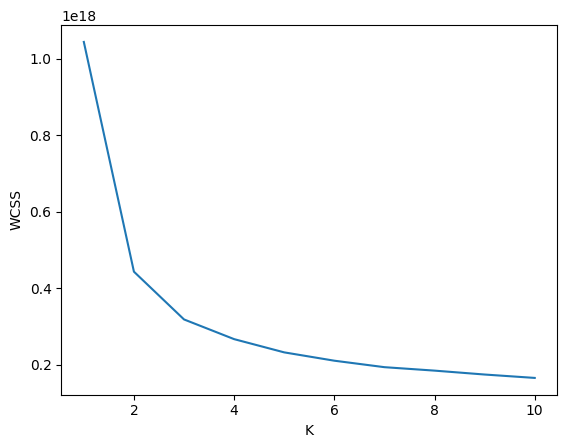

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []

for k in range(1,11):
    model = KMeans(
        n_clusters=k,
        random_state=42
    )

    model.fit(X)

    wcss.append(model.inertia_)

plt.plot(range(1,11), wcss)
plt.xlabel("K")
plt.ylabel("WCSS")
plt.show()

   loan_id  no_of_dependents      education  self_employed   income_annum  \
0        1                 2       Graduate             No        9600000   
1        2                 0   Not Graduate            Yes        4100000   
2        3                 3       Graduate             No        9100000   
3        4                 3       Graduate             No        8200000   
4        5                 5   Not Graduate            Yes        9800000   

    loan_amount   loan_term   cibil_score   residential_assets_value  \
0      29900000          12           778                    2400000   
1      12200000           8           417                    2700000   
2      29700000          20           506                    7100000   
3      30700000           8           467                   18200000   
4      24200000          20           382                   12400000   

    commercial_assets_value   luxury_assets_value   bank_asset_value  \
0                  17600000     

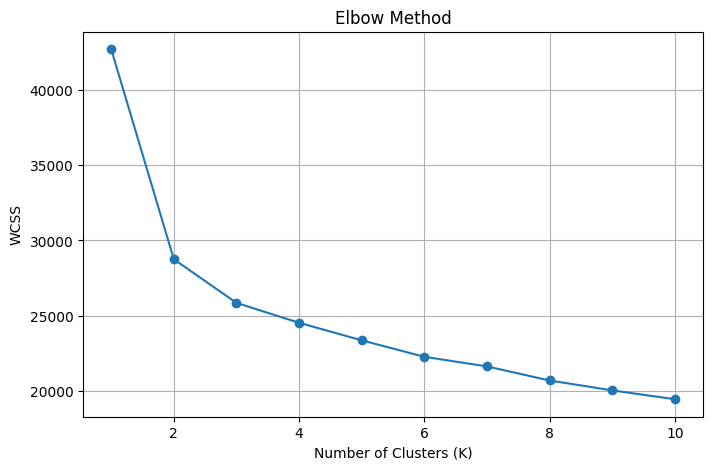

   loan_id  no_of_dependents      education  self_employed   income_annum  \
0        1                 2       Graduate             No        9600000   
1        2                 0   Not Graduate            Yes        4100000   
2        3                 3       Graduate             No        9100000   
3        4                 3       Graduate             No        8200000   
4        5                 5   Not Graduate            Yes        9800000   

    loan_amount   loan_term   cibil_score   residential_assets_value  \
0      29900000          12           778                    2400000   
1      12200000           8           417                    2700000   
2      29700000          20           506                    7100000   
3      30700000           8           467                   18200000   
4      24200000          20           382                   12400000   

    commercial_assets_value   luxury_assets_value   bank_asset_value  \
0                  17600000     

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


df = pd.read_csv("loan_approval.csv")

print(df.head())
print("-------------------------------------------------------------------------")

X = df.select_dtypes(include=["int64","float64"])

print(X.head())
print("-------------------------------------------------------------------------")


scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


wcss = []

for k in range(1,11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)


plt.figure(figsize=(8,5))

plt.plot(range(1,11), wcss, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.grid(True)
plt.show()


kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

clusters = kmeans.fit_predict(X_scaled)

df["Cluster"] = clusters

print(df.head())


print(df["Cluster"].value_counts())


cluster_summary = df.groupby("Cluster").mean(numeric_only=True)

print(cluster_summary)


print("Cluster Centers:")

print(kmeans.cluster_centers_)




In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import (train_test_split,GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

df = pd.read_csv("loan_approval.csv")
df.columns = df.columns.str.strip()

X = df.drop("loan_status",axis = 1)
y = df["loan_status"]

le = LabelEncoder()
X["education"] = le.fit_transform(X["education"])
X["self_employed"] = le.fit_transform(X["self_employed"])
y = le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)

model = RandomForestClassifier()

p_grid = {"max_depth":[3,5,7,10],"n_estimators":[50,100,200]}
grid = GridSearchCV(estimator = model, param_grid = p_grid,cv = 5,scoring = "accuracy")

grid.fit(X_train,y_train)
print(grid.best_params_)
print(grid.best_score_)

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

{'max_depth': 10, 'n_estimators': 100}
0.9748169838945827


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import (train_test_split,cross_val_score,GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier


df = pd.read_csv("loan_approval.csv")
df.columns = df.columns.str.strip()

X = df.drop("loan_status",axis = 1)
y = df["loan_status"]

le = LabelEncoder()
X["education"] = le.fit_transform(X["education"])
X["self_employed"] = le.fit_transform(X["self_employed"])
y = le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size =0.2,random_state = 42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test =scaler.fit_transform(X_test)

model = RandomForestClassifier()

scores = cross_val_score(model,X_train,y_train,cv = 5)
model.fit(X_train,y_train)

y_pred = model.predict(X_test)
print(scores.mean())

0.9780380673499268


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import (train_test_split,cross_val_score,GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score,recall_score,precision_score,f1_score,confusion_matrix)


df = pd.read_csv("loan_approval.csv")
df.columns = df.columns.str.strip()

X = df.drop("loan_status",axis = 1)
y = df["loan_status"]

le = LabelEncoder()
X["education"] = le.fit_transform(X["education"])
X["self_employed"] = le.fit_transform(X["self_employed"])
y = le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size =0.2,random_state = 42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test =scaler.fit_transform(X_test)

model = DecisionTreeClassifier()

param_grid = {
    "max_depth" : [3,5,7,9,10],
    "criterion" : ["gini","entropy"]
}

grid = GridSearchCV(model,param_grid = param_grid,cv = 5)
grid.fit(X_train,y_train)

print(grid.best_params_)
print(grid.best_score_)

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)

print(f"accuracy: {accuracy}")
print(f"precision : {precision}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")
print(cm)
print("\n")

print("train score :",best_model.score(X_train,y_train))
print(f"test score :{best_model.score(X_test,y_test)}")

{'criterion': 'entropy', 'max_depth': 10}
0.9736456808199122
accuracy: 0.9742388758782201
precision : 0.9900662251655629
recall : 0.940251572327044
f1-score : 0.964516129032258
[[533   3]
 [ 19 299]]


train score : 0.9915080527086384
test score :0.9742388758782201


In [ ]:
import pandas as pd
from sklearn.preprocessing import (LabelEncoder,StandardScaler)
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score,recall_score,precision_score,f1_score,confusion_matrix)

df = pd.read_csv("loan_approval.csv")
df.columns = df.columns.str.strip()

X = df.drop("loan_status",axis =1)
y =df["loan_status"]

le = LabelEncoder()
X["education"] = le.fit_transform(X["education"])
X["self_employed"] = le.fit_transform(df["self_employed"])
y = le.fit_transform(y)

X_train,X_test,y_train,y_test =train_test_split(X,y,test_size = 0.2,random_state = 42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)

model =XGBClassifier(n_estimators = 100,max_depth = 5,learning_rate = 0.1,random_state =42)
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)

print(f"accuracy: {accuracy}")
print(f"precision : {precision}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")
print(cm)
print("\n")

print("train score :",model.score(X_train,y_train))
print(f"test score :{model.score(X_test,y_test)}")

accuracy: 0.9789227166276346
precision : 0.9807692307692307
recall : 0.9622641509433962
f1-score : 0.9714285714285714
[[530   6]
 [ 12 306]]


train score : 1.0
test score :0.9789227166276346


In [ ]:
import pandas as pd
from sklearn.preprocessing import (LabelEncoder,StandardScaler)
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score,recall_score,precision_score,f1_score,confusion_matrix)
from imblearn.over_sampling import SMOTE

df = pd.read_csv("loan_approval.csv")
df.columns = df.columns.str.strip()

X = df.drop("loan_status",axis =1)
y =df["loan_status"]

le = LabelEncoder()
X["education"] = le.fit_transform(X["education"])
X["self_employed"] = le.fit_transform(df["self_employed"])
y = le.fit_transform(y)

X_train,X_test,y_train,y_test =train_test_split(X,y,test_size = 0.2,random_state = 42)

smote = SMOTE(random_state = 42)
X_train_smote,y_train_smote = smote.fit_resample(X_train,y_train)



model = XGBClassifier(max_depth = 5,n_estimators = 100,learning_rate=0.1)
model.fit(X_train_smote,y_train_smote)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)

precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)

print(f"accuracy: {accuracy}")
print(f"precision : {precision}")
print(f"recall : {recall}")
print(f"f1-score : {f1}")
print(cm)
print("\n")

print("train score :",model.score(X_train,y_train))
print(f"test score :{model.score(X_test,y_test)}")

accuracy: 0.9824355971896955
precision : 0.9779179810725552
recall : 0.9748427672955975
f1-score : 0.9763779527559056
[[529   7]
 [  8 310]]


train score : 1.0
test score :0.9824355971896955


In [ ]:
import pandas as pd
from sklearn.preprocessing import (LabelEncoder,StandardScaler)
from sklearn.model_selection import (train_test_split,GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

df = pd.read_csv("loan_approval.csv")
df.columns = df.columns.str.strip()

X = df.drop("loan_status",axis = 1)
y = df["loan_status"]

le = LabelEncoder()
X["education"] = le.fit_transform(X["education"])
X["self_employed"] = le.fit_transform(df["self_employed"])
y = le.fit_transform(y)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state  = 42)

pipe = Pipeline([
    ("scaler",StandardScaler()),
    ("model",SVC())
])

param_grid = {
    "model__C" : [0.1,1,10],
    "model__kernel" : ["linear","rbf"]
}

grid = GridSearchCV(estimator = pipe,param_grid = param_grid,cv = 5,scoring = "accuracy",n_jobs = -1)

grid.fit(X_train,y_train)

y_pred = grid.predict(X_test)

print(grid.best_params_)

print(grid.best_score_)
print(accuracy_score(y_test,y_pred))

{'model__C': 10, 'model__kernel': 'rbf'}
0.9414348462664714
0.9344262295081968


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report)

df = pd.read_csv("spam.csv", encoding='latin1')
df.columns = df.columns.str.strip()

print(df.shape)
print(df.columns)
df = df.drop(["Unnamed: 2","Unnamed: 3","Unnamed: 4"],axis = 1)
print(df.head())
print("************************************")

X = df["Message"]
y = df["status"]

le = LabelEncoder()
y = le.fit_transform(y)

print(f"0: {le.classes_[0]}")
print(f"1: {le.classes_[1]}")
print("************************************")

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)

tfidf = TfidfVectorizer()
X_train = tfidf.fit_transform(X_train)
X_test = tfidf.transform(X_test)

model = MultinomialNB()
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)
c_r = classification_report(y_test,y_pred)


print("Acc:",accuracy)
print("conf_matrix :",cm)
print(c_r)

print("train score :",model.score(X_train,y_train))
print(f"test score :{model.score(X_test,y_test)}")

print("************************************")

message = ["congratulations! click on this link to get free money"]
message_tfidf =tfidf.transform(message)
prediction = model.predict(message_tfidf)

print("Prediction:")
print(prediction)
print(le.inverse_transform(prediction))

(5572, 5)
Index(['status', 'Message', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')
  status                                            Message
0    ham  Go until jurong point, crazy.. Available only ...
1    ham                      Ok lar... Joking wif u oni...
2   spam  Free entry in 2 a wkly comp to win FA Cup fina...
3    ham  U dun say so early hor... U c already then say...
4    ham  Nah I don't think he goes to usf, he lives aro...
************************************
0: ham
1: spam
************************************
Acc: 0.9623318385650225
conf_matrix : [[965   0]
 [ 42 108]]
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       965
           1       1.00      0.72      0.84       150

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115

train score : 0.9728516939645502
test score :0.9623318385650225
**

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report)
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

df = pd.read_csv("spam.csv", encoding='latin1')
df.columns = df.columns.str.strip()

print(df.shape)
print(df.columns)
df = df.drop(["Unnamed: 2","Unnamed: 3","Unnamed: 4"],axis = 1)
print(df.head())
print("************************************")

X = df["Message"]
y = df["status"]

le = LabelEncoder()
y = le.fit_transform(y)

print(f"0: {le.classes_[0]}")
print(f"1: {le.classes_[1]}")
print("************************************")

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)

tfidf = TfidfVectorizer()
X_train_transformed = tfidf.fit_transform(X_train)
X_test_transformed = tfidf.transform(X_test)

smote = SMOTE()
X_train_smote,y_train_smote = smote.fit_resample(X_train_transformed,y_train)


model = LogisticRegression()
model.fit(X_train_smote,y_train_smote)

y_pred = model.predict(X_test_transformed)

accuracy = accuracy_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)
c_r = classification_report(y_test,y_pred)


print("Acc:",accuracy)
print("conf_matrix :",cm)
print(c_r)

print("train score :",model.score(X_train_transformed,y_train))
print(f"test score :{model.score(X_test_transformed,y_test)}")

print("************************************")

message = ["congratulations! click on this link to get free money"]
message_tfidf =tfidf.transform(message)
prediction = model.predict(message_tfidf)

print("Prediction:")
print(prediction)
print(le.inverse_transform(prediction))

(5572, 5)
Index(['status', 'Message', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')
  status                                            Message
0    ham  Go until jurong point, crazy.. Available only ...
1    ham                      Ok lar... Joking wif u oni...
2   spam  Free entry in 2 a wkly comp to win FA Cup fina...
3    ham  U dun say so early hor... U c already then say...
4    ham  Nah I don't think he goes to usf, he lives aro...
************************************
0: ham
1: spam
************************************
Acc: 0.9775784753363229
conf_matrix : [[955  10]
 [ 15 135]]
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       965
           1       0.93      0.90      0.92       150

    accuracy                           0.98      1115
   macro avg       0.96      0.94      0.95      1115
weighted avg       0.98      0.98      0.98      1115

train score : 0.9928202827013687
test score :0.9775784753363229
**